## SST

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import mikeio
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import modelskill as ms
import torch

import sys
from pathlib import Path
import os

from scipy.io import loadmat
from helper import plot_training_curves, evaluate_model, plot_reconstruction

# Add parent directory to path to access src module
sys.path.insert(0, str(Path.cwd().parent.parent))
DATA_DIR = Path.cwd() / "datasets"  

from src.datamanager import DataManager
from src.engine import SHREDEngine
from src.train import fit, evaluate
from src.mSHRED.mSHRED import mSHRED

# get device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

## Exploration

Shape of X_raw: (9490, 64800) after permutation: 
[18 25 23  3 24 11  6 19 13  8 16 20 22 12  1 14 15 21  0  9 17  7  2  4
  5 10]
Percentage of broken sensors: 20.15%

Shape of X_raw: (9490, 64800)
Shape of X_clean: (9490, 41027)
Shape of sensor locations: (9490, 10)


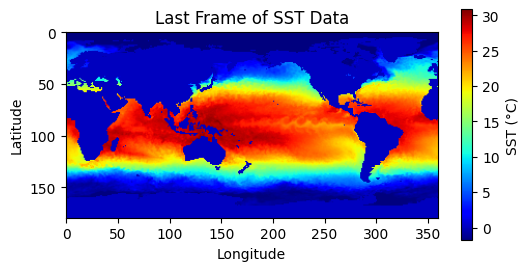

In [3]:
# Load SST data -> X RAW
X_raw = np.load(DATA_DIR / "sst_all_ROM.npy")
#shuffle the data along the year axis
permutation = np.random.permutation(X_raw.shape[0])
X_raw = X_raw[permutation]
X_raw = X_raw.reshape(-1, 180 * 360)  
print(f"Shape of X_raw: {X_raw.shape} after permutation: \n{permutation}")

# Load SST data -> X CLEAN
mean_X = np.mean(X_raw, axis=0)
sst_locs = np.where(mean_X != 0)[0]
X_clean = X_raw[:, sst_locs]

# Extract sensor locations and number of sensors
num_sensors = 10
sensor_locations = np.random.choice(X_clean.shape[1], size=num_sensors, replace=False)
sensor = X_clean[:, sensor_locations]

# Broken sensor data simulation
# Randomly select 30% of the sensors to be broken at each time step
broken_sensor_mask = np.random.rand(sensor.shape[0], sensor.shape[1]) < 0.2
sensor[broken_sensor_mask] = np.nan  # Set broken sensor readings to NaN
print(f"Percentage of broken sensors: {np.mean(broken_sensor_mask) * 100:.2f}%\n")

# Print shapes of the datasets
print(f"Shape of X_raw: {X_raw.shape}")
print(f"Shape of X_clean: {X_clean.shape}")
print(f"Shape of sensor locations: {sensor.shape}")

# Plot the last frame of the data
plt.figure(figsize=(6, 3))
plt.imshow(X_raw[-1, :].reshape(180, 360), cmap='jet')
plt.colorbar(label='SST (°C)')
plt.title('Last Frame of SST Data')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

In [4]:
ERRORS = []

# DataManager
LAGS = 26

TRAIN_SIZE = 0.70        # percentage of data used for training 
VAL_SIZE = 0.15          # percentage of data used for validation
TEST_SIZE = 0.15         # percentage of data used for testing

COMPRESS_SST = 800

# Training
OPTIMIZER = "AdamW"     # optimizer to use
LEARNING_RATE = 5e-4    # learning rate for training
NUM_EPOCHS = 400        # maximum number of epochs for training
LR_SCHEDULER = "CosineAnnealingLR"      # learning rate scheduler to use
SCHEDULER_STEP_SIZE = NUM_EPOCHS        # step size for learning rate scheduler (if applicable)

BATCH_SIZE = 32         # batch size for training
PATIENCE = 80           # number of epochs with no improvement on validation loss before stopping training
VERBOSE_TRAIN = True

# Architecture
ENCODER_DEPTH = 2               # number of encoder layers
HIDDEN_SIZE = 32                # hidden size for encoder and decoder layers
N_HEADS = 4                     # number of attention heads (if using a transformer-based architecture)
DIM_FEEDFORWARD = 48            # dimension of feedforward network in transformer (if using a transformer-based architecture)
DECODER = "cnn"                 # type of decoder to use (mpl or cnn)   
DECODER_HIDDEN_SIZES = [256]    # hidden sizes for decoder layers 
DROPOUT = 0.1                   # dropout rate for encoder and decoder layers
MASKING_TYPE = "mask_data"      # type of masking to apply to inputs during training (mask_data, mask_data_random, etc.)

## (T.1.A): Median imputer

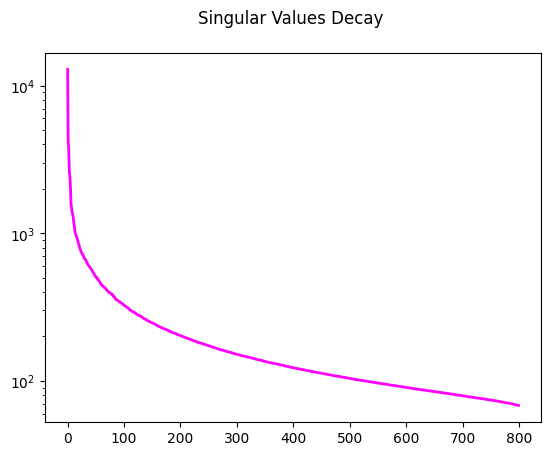

Residual energy of Surface elevation after keeping 800 modes: 1.3748 %

Datasets: ['Surface elevation']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([6643, 26, 10]) -> torch.Size([6643, 800])
Val:	 torch.Size([1423, 26, 10]) -> torch.Size([1423, 800])
Test:	 torch.Size([1424, 26, 10]) -> torch.Size([1424, 800])

Input shape for the model: 10
Output shape for the model: 800


In [5]:
# Data manager
manager = DataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(X_clean, id="Surface elevation", compress=COMPRESS_SST, measurements=sensor, imputer="median", verbose=True)
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose=True)

# network input and output shapes
nn_input_shape = train_dataset[0][0].shape[1]
nn_output_shape = train_dataset[0][1].shape[0]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)

Starting training...


Training:  35%|███▍      | 139/400 [03:59<07:29,  1.72s/it, Train Loss=0.01340, Val Loss=0.01898, Patience=79, Best Val Loss=0.01795, LR=3.63e-04]

Early stopping at epoch 140
Training completed with best validation loss: 0.0179


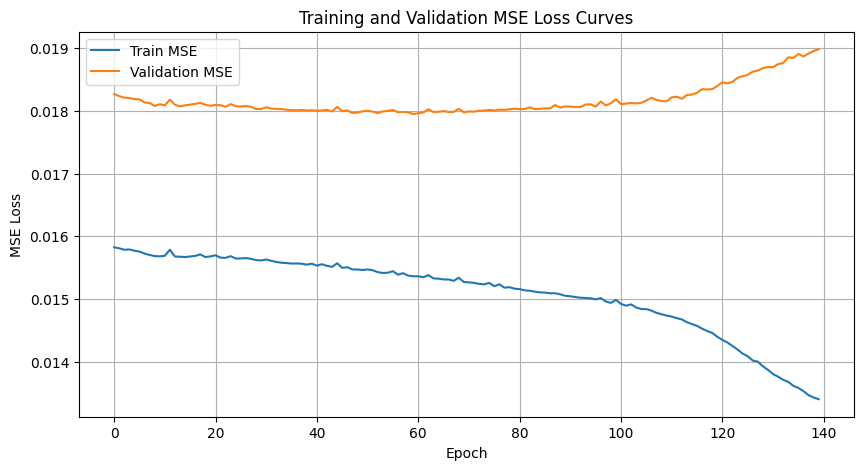

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.015361,0.01795,0.019344,0.255408,0.271153,0.285075


In [6]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=False,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
)

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.1.A): median imputation for missing sensors"
 )

ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

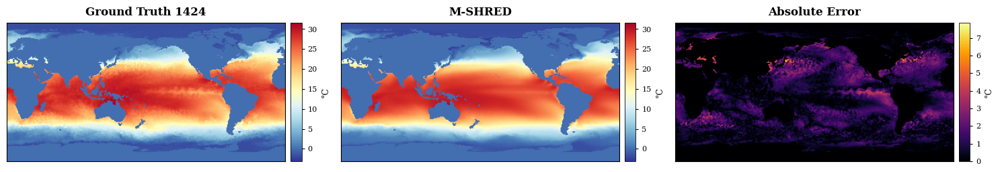

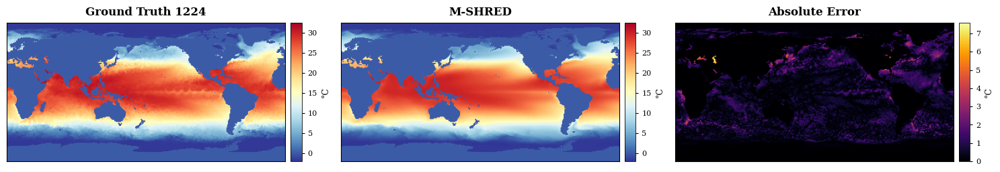

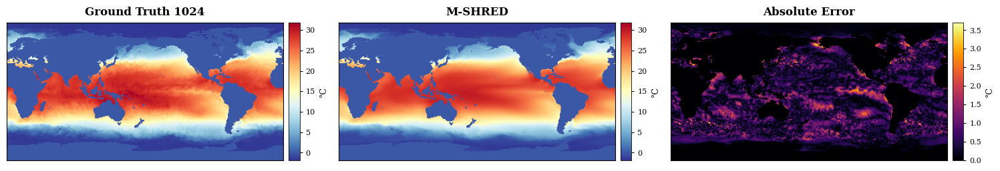

In [7]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
for id in range(3):
    plot_reconstruction(test_reconstruction, X_raw, sst_locs, index=-id*200)

## (T.1.B): Mean imputer

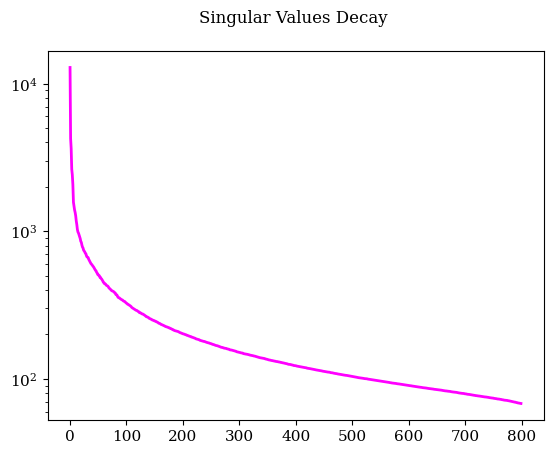

Residual energy of Surface elevation after keeping 800 modes: 1.3753 %

Datasets: ['Surface elevation']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([6643, 26, 10]) -> torch.Size([6643, 800])
Val:	 torch.Size([1423, 26, 10]) -> torch.Size([1423, 800])
Test:	 torch.Size([1424, 26, 10]) -> torch.Size([1424, 800])

Input shape for the model: 10
Output shape for the model: 800


In [8]:
# Data manager
manager = DataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(X_clean, id="Surface elevation", compress=COMPRESS_SST, measurements=sensor, imputer="mean", verbose=True)
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose=True)

# network input and output shapes
nn_input_shape = train_dataset[0][0].shape[1]
nn_output_shape = train_dataset[0][1].shape[0]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)

Starting training...


Training:  33%|███▎      | 133/400 [03:52<07:47,  1.75s/it, Train Loss=0.01331, Val Loss=0.01898, Patience=79, Best Val Loss=0.01799, LR=3.74e-04]

Early stopping at epoch 134
Training completed with best validation loss: 0.0180


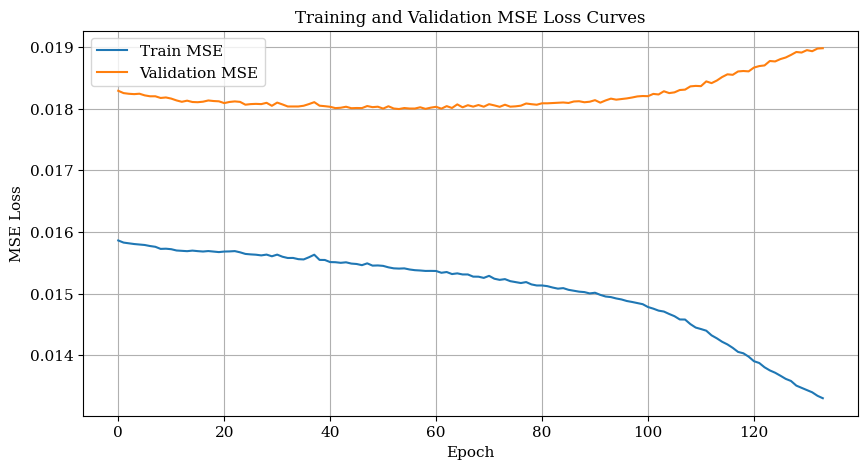

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.015361,0.017950,0.019344,0.255408,0.271153,0.285075
1,(mSHRED): TR+cnn,(T.1.B): mean imputation for missing sensors,0.015406,0.017993,0.019442,0.255280,0.271323,0.284267


In [9]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=False,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
)

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.1.B): mean imputation for missing sensors"
 )

ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

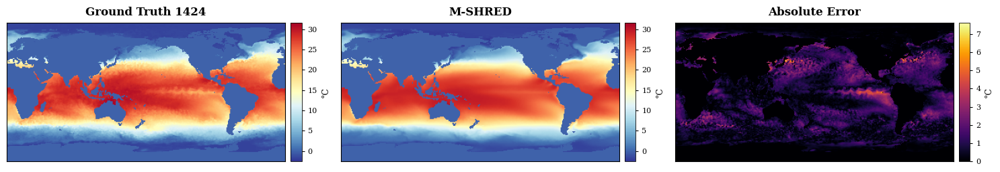

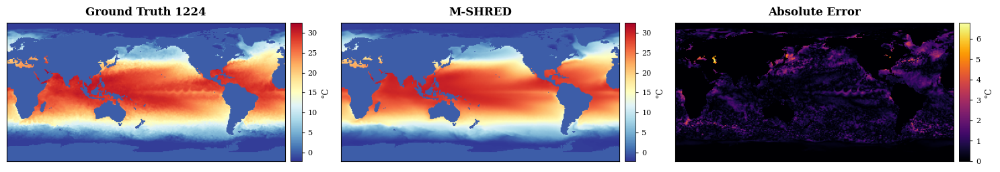

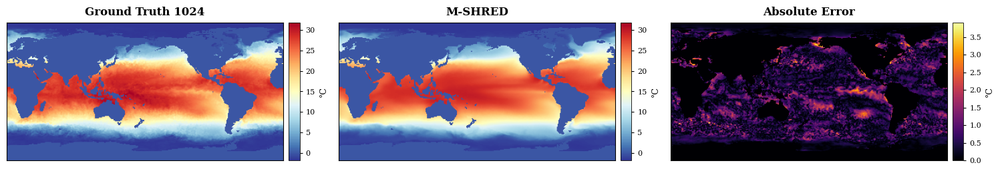

In [10]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
for id in range(3):
    plot_reconstruction(test_reconstruction, X_raw, sst_locs, index=-id*200)

## (T.1.C): Last value imputer

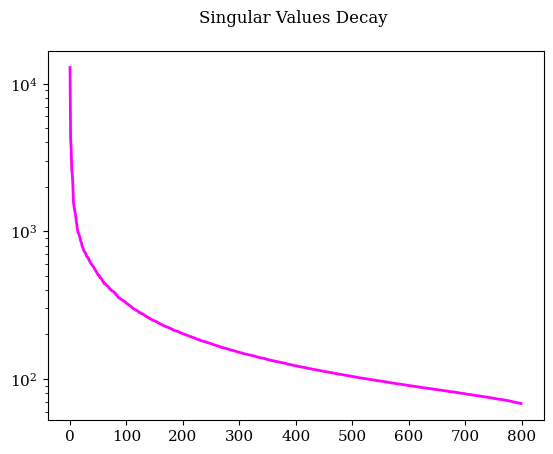

Residual energy of Surface elevation after keeping 800 modes: 1.3754 %

Datasets: ['Surface elevation']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([6643, 26, 10]) -> torch.Size([6643, 800])
Val:	 torch.Size([1423, 26, 10]) -> torch.Size([1423, 800])
Test:	 torch.Size([1424, 26, 10]) -> torch.Size([1424, 800])

Input shape for the model: 10
Output shape for the model: 800


In [11]:
# Data manager
manager = DataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(X_clean, id="Surface elevation", compress=COMPRESS_SST, measurements=sensor, imputer="last_value", verbose=True)
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose=True)

# network input and output shapes
nn_input_shape = train_dataset[0][0].shape[1]
nn_output_shape = train_dataset[0][1].shape[0]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)

Starting training...


Training:  30%|██▉       | 119/400 [03:24<08:02,  1.72s/it, Train Loss=0.01280, Val Loss=0.01926, Patience=79, Best Val Loss=0.01799, LR=3.97e-04]

Early stopping at epoch 120
Training completed with best validation loss: 0.0180


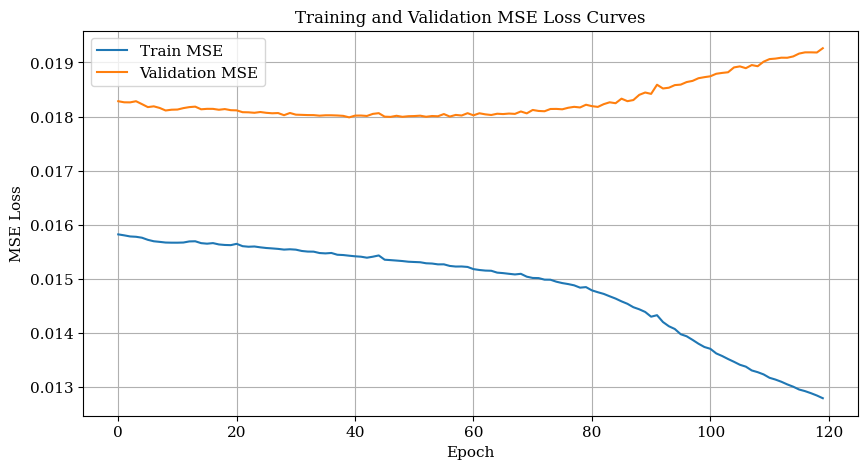

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.015361,0.017950,0.019344,0.255408,0.271153,0.285075
1,(mSHRED): TR+cnn,(T.1.B): mean imputation for missing sensors,0.015406,0.017993,0.019442,0.255280,0.271323,0.284267
2,(mSHRED): TR+cnn,(T.1.C): last-value imputation for missing sen...,0.015430,0.017986,0.019407,0.255855,0.271408,0.284596


In [12]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=False,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
)

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.1.C): last-value imputation for missing sensors"
 )

ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

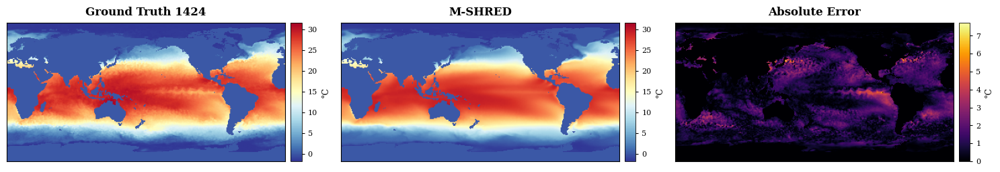

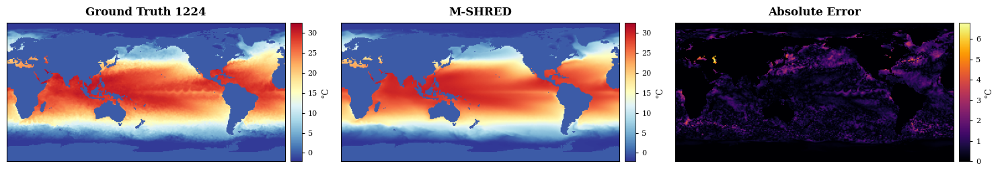

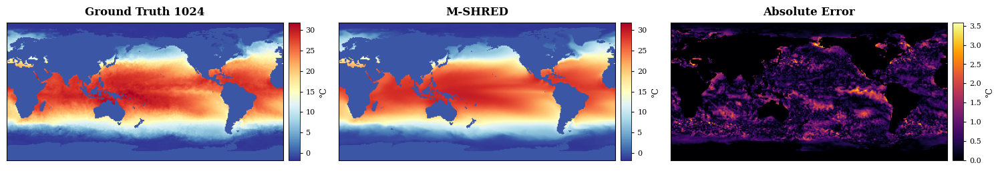

In [13]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
for id in range(3):
    plot_reconstruction(test_reconstruction, X_raw, sst_locs, index=-id*200)

## (T.2.A) GRUD

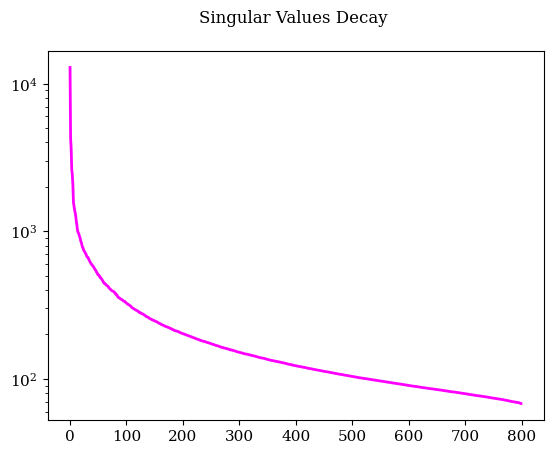

Residual energy of Surface elevation after keeping 800 modes: 1.3751 %

Datasets: ['Surface elevation']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([6643, 4, 26, 10]) -> torch.Size([6643, 800])
Val:	 torch.Size([1423, 4, 26, 10]) -> torch.Size([1423, 800])
Test:	 torch.Size([1424, 4, 26, 10]) -> torch.Size([1424, 800])

Input shape for the model: 10
Output shape for the model: 800


In [14]:
# Data manager
manager = DataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(X_clean, id="Surface elevation", compress=COMPRESS_SST, measurements=sensor, verbose=True)
# prepare datasets
train_dataset, val_dataset, test_dataset, X_mean = manager.prepare(verbose=True, masking_type="grud")

# network input and output shapes
nn_input_shape = train_dataset[0][0].shape[-1]
nn_output_shape = train_dataset[0][1].shape[0]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)

Starting training...


Training:  27%|██▋       | 109/400 [03:39<09:46,  2.01s/it, Train Loss=0.01504, Val Loss=0.01835, Patience=79, Best Val Loss=0.01795, LR=4.12e-04]

Early stopping at epoch 110
Training completed with best validation loss: 0.0179


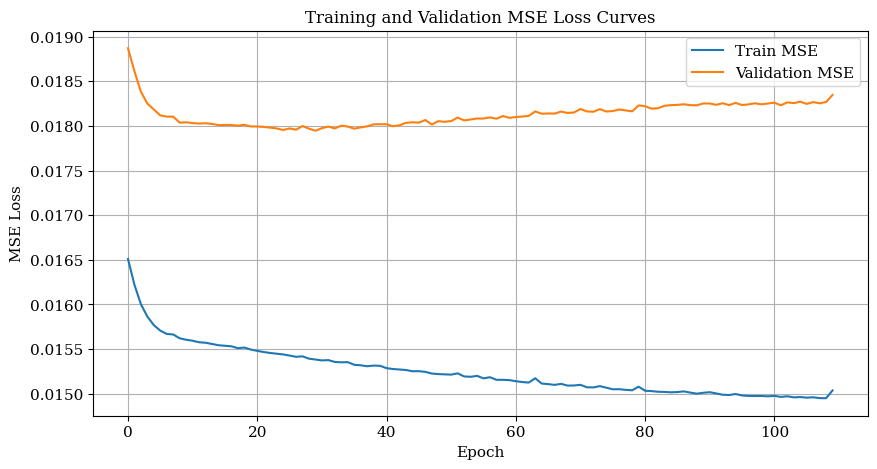

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.015361,0.017950,0.019344,0.255408,0.271153,0.285075
1,(mSHRED): TR+cnn,(T.1.B): mean imputation for missing sensors,0.015406,0.017993,0.019442,0.255280,0.271323,0.284267
2,(mSHRED): TR+cnn,(T.1.C): last-value imputation for missing sen...,0.015430,0.017986,0.019407,0.255855,0.271408,0.284596
3,(mSHRED): GRUD+cnn,(T.2.A): GRUD,0.015382,0.017947,0.019429,0.255484,0.271606,0.284615


In [15]:
# GRUD TRAINING
model_args = dict(
    # Encoder
    encoder="grud", input_size=nn_input_shape, hidden_size=HIDDEN_SIZE, X_mean=X_mean,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
)

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): GRUD+{DECODER}", type="(T.2.A): GRUD"
 )

ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

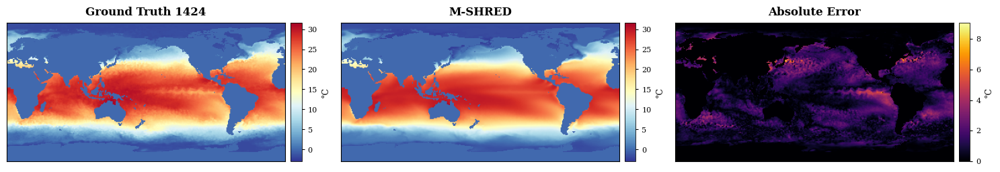

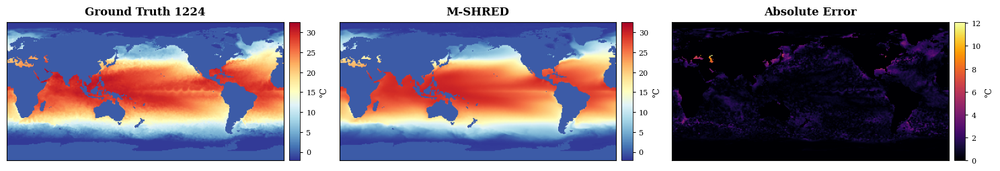

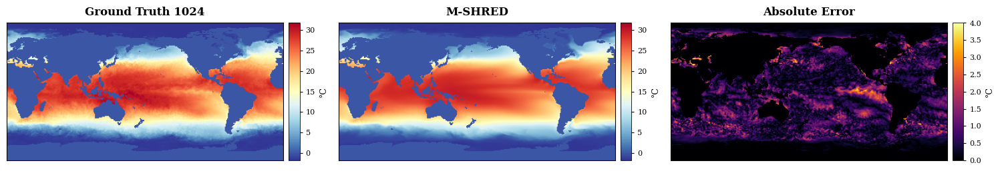

In [16]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
for id in range(3):
    plot_reconstruction(test_reconstruction, X_raw, sst_locs, index=-id*200)

## (T.2.B): Attn-GRUD

Starting training...


Training:  27%|██▋       | 107/400 [05:29<15:02,  3.08s/it, Train Loss=0.01497, Val Loss=0.01869, Patience=79, Best Val Loss=0.01804, LR=4.15e-04]

Early stopping at epoch 108
Training completed with best validation loss: 0.0180


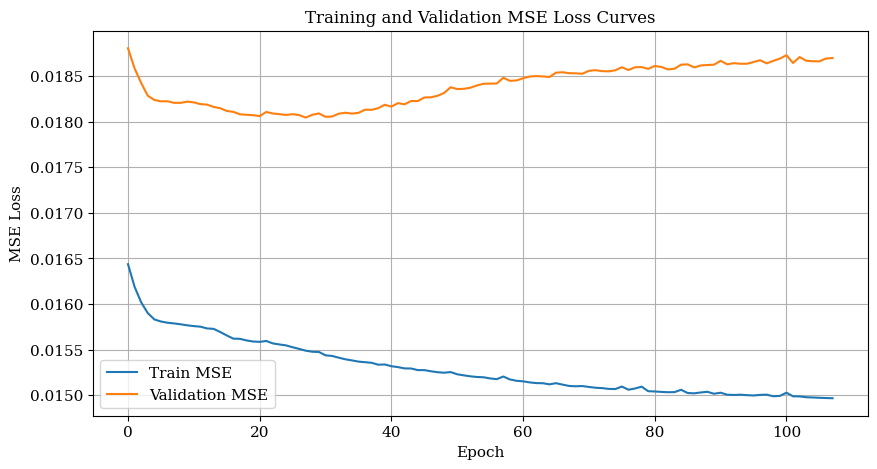

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.015361,0.017950,0.019344,0.255408,0.271153,0.285075
1,(mSHRED): TR+cnn,(T.1.B): mean imputation for missing sensors,0.015406,0.017993,0.019442,0.255280,0.271323,0.284267
2,(mSHRED): TR+cnn,(T.1.C): last-value imputation for missing sen...,0.015430,0.017986,0.019407,0.255855,0.271408,0.284596
3,(mSHRED): GRUD+cnn,(T.2.A): GRUD,0.015382,0.017947,0.019429,0.255484,0.271606,0.284615
4,(mSHRED): Attn-GRUD+cnn,(T.2.B): Attn-GRUD,0.015489,0.018043,0.019502,0.256395,0.272255,0.285157


In [17]:
# Attn-GRUD TRAINING
model_args = dict(
    # Encoder
    encoder="att_grud", input_size=nn_input_shape, hidden_size=HIDDEN_SIZE, X_mean=X_mean,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
)

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): Attn-GRUD+{DECODER}", type="(T.2.B): Attn-GRUD"
 )

ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

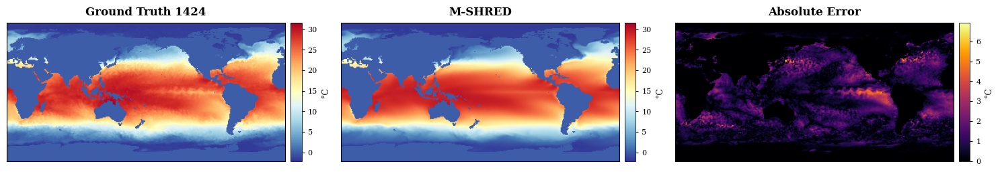

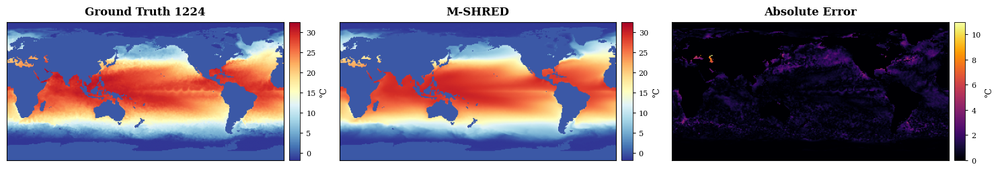

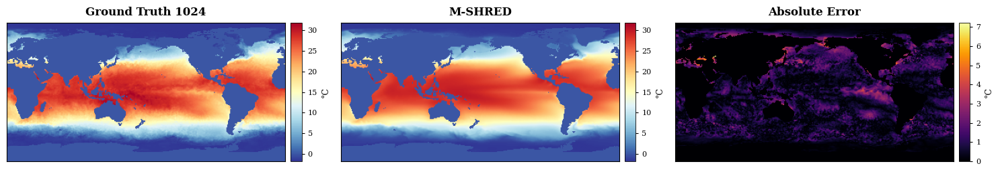

In [18]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
for id in range(3):
    plot_reconstruction(test_reconstruction, X_raw, sst_locs, index=-id*200)

## (T.3.A): Masking

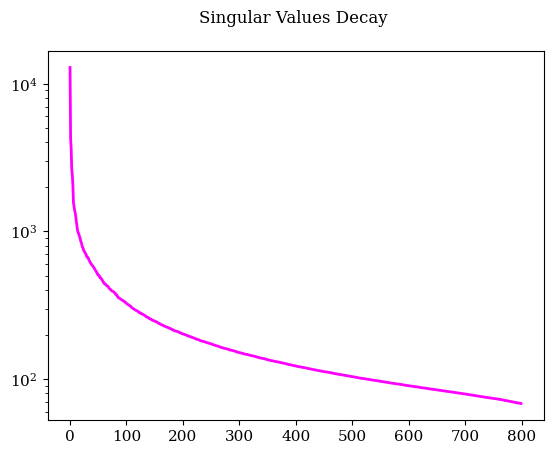

Residual energy of Surface elevation after keeping 800 modes: 1.3753 %

Datasets: ['Surface elevation']

Number of nan values in sensor measurements after masking: 19125

Data shapes after preparation:
Train:	 torch.Size([6643, 26, 10]) -> torch.Size([6643, 800])
Val:	 torch.Size([1423, 26, 10]) -> torch.Size([1423, 800])
Test:	 torch.Size([1424, 26, 10]) -> torch.Size([1424, 800])

Input shape for the model: 10
Output shape for the model: 800


In [19]:
# Data manager
manager = DataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(X_clean, id="Surface elevation", compress=COMPRESS_SST, measurements=sensor, verbose=True)
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose=True, masking_type=MASKING_TYPE)

# network input and output shapes
nn_input_shape = train_dataset.X.shape[-1]
nn_output_shape = train_dataset.Y.shape[-1]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)

Starting training...


Training:  34%|███▎      | 134/400 [03:56<07:48,  1.76s/it, Train Loss=0.01365, Val Loss=0.01876, Patience=79, Best Val Loss=0.01799, LR=3.72e-04]

Early stopping at epoch 135
Training completed with best validation loss: 0.0180


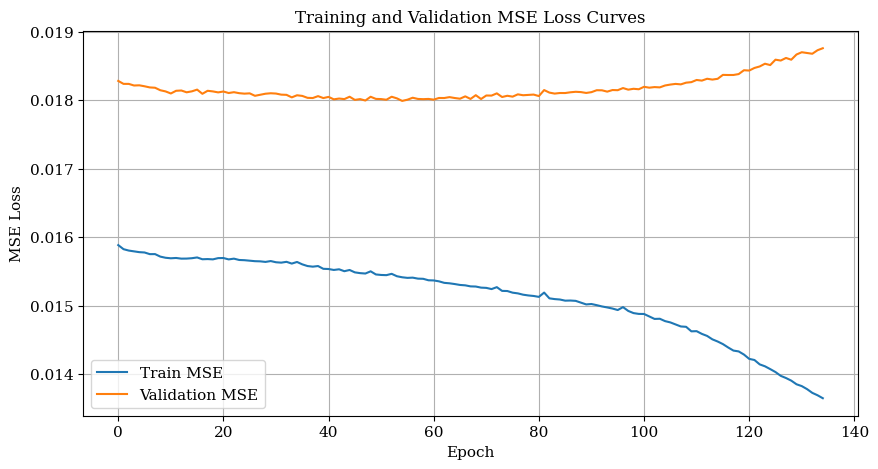

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.015361,0.017950,0.019344,0.255408,0.271153,0.285075
1,(mSHRED): TR+cnn,(T.1.B): mean imputation for missing sensors,0.015406,0.017993,0.019442,0.255280,0.271323,0.284267
2,(mSHRED): TR+cnn,(T.1.C): last-value imputation for missing sen...,0.015430,0.017986,0.019407,0.255855,0.271408,0.284596
3,(mSHRED): GRUD+cnn,(T.2.A): GRUD,0.015382,0.017947,0.019429,0.255484,0.271606,0.284615
4,(mSHRED): Attn-GRUD+cnn,(T.2.B): Attn-GRUD,0.015489,0.018043,0.019502,0.256395,0.272255,0.285157
5,(mSHRED): TR+cnn,(T.3.A): masking,0.015415,0.017991,0.019457,0.256017,0.271837,0.285440


In [20]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=False,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
)
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    masking_type=MASKING_TYPE,
)

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.3.A): masking", masking_type=MASKING_TYPE
)

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

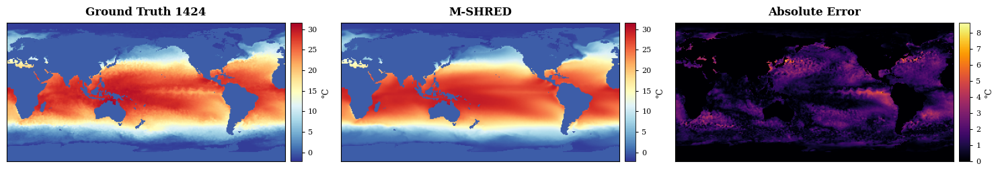

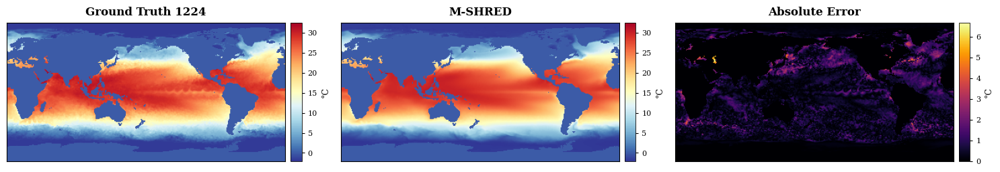

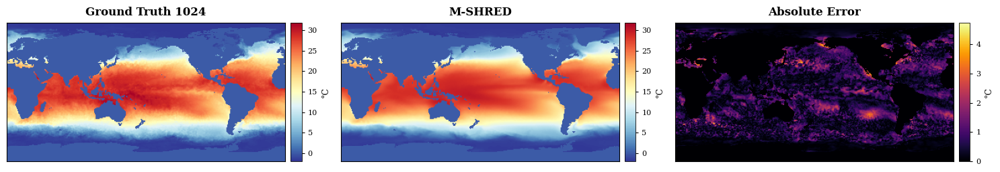

In [21]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
for id in range(3):
    plot_reconstruction(test_reconstruction, X_raw, sst_locs, index=-id*200)

## (T.3.B): Masking x2 channels

Starting training...


Training:  33%|███▎      | 131/400 [03:56<08:06,  1.81s/it, Train Loss=0.01379, Val Loss=0.01872, Patience=79, Best Val Loss=0.01798, LR=3.77e-04]

Early stopping at epoch 132
Training completed with best validation loss: 0.0180


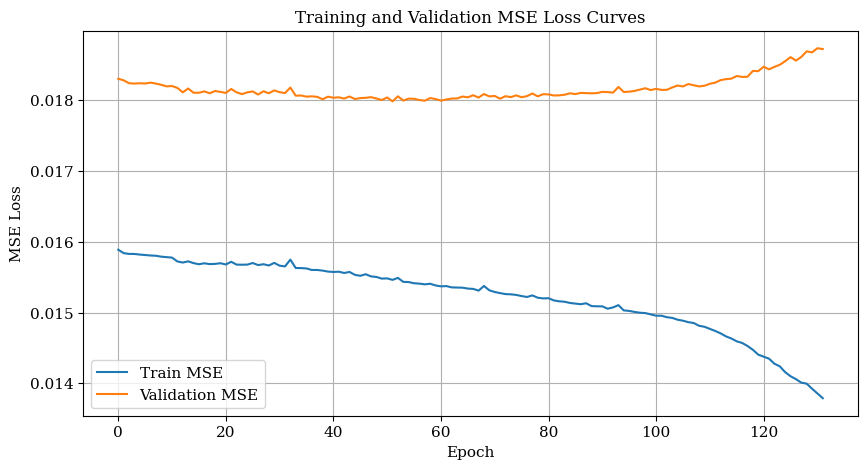

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.015361,0.017950,0.019344,0.255408,0.271153,0.285075
1,(mSHRED): TR+cnn,(T.1.B): mean imputation for missing sensors,0.015406,0.017993,0.019442,0.255280,0.271323,0.284267
2,(mSHRED): TR+cnn,(T.1.C): last-value imputation for missing sen...,0.015430,0.017986,0.019407,0.255855,0.271408,0.284596
3,(mSHRED): GRUD+cnn,(T.2.A): GRUD,0.015382,0.017947,0.019429,0.255484,0.271606,0.284615
4,(mSHRED): Attn-GRUD+cnn,(T.2.B): Attn-GRUD,0.015489,0.018043,0.019502,0.256395,0.272255,0.285157
5,(mSHRED): TR+cnn,(T.3.A): masking,0.015415,0.017991,0.019457,0.256017,0.271837,0.285440
6,(mSHRED): TR+cnn,(T.3.B): masking x2 channels,0.015461,0.017983,0.019431,0.256416,0.271805,0.285267


In [22]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=True,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
 )
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    masking_type=MASKING_TYPE,
 )

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.3.B): masking x2 channels", masking_type=MASKING_TYPE
 )

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

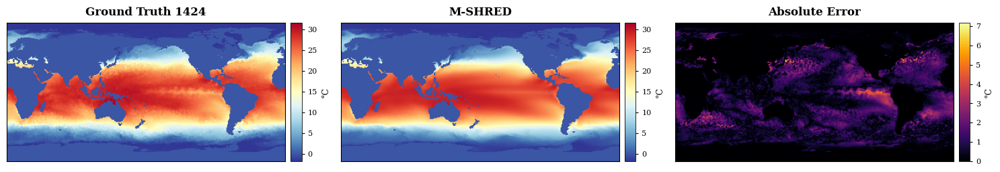

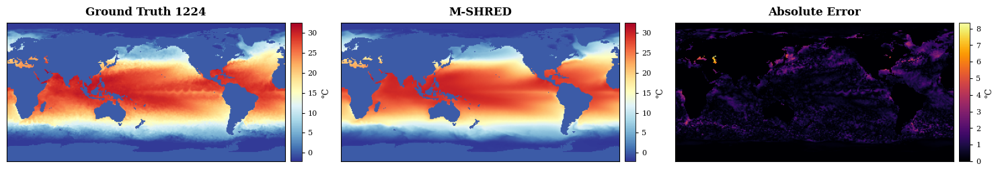

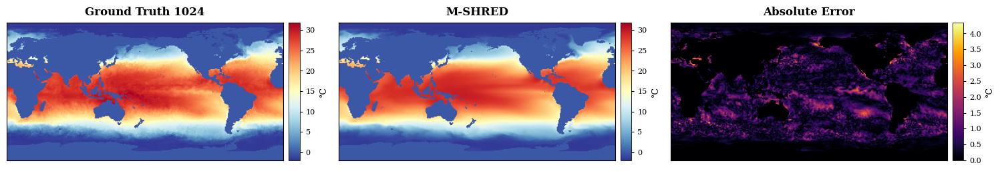

In [23]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
for id in range(3):
    plot_reconstruction(test_reconstruction, X_raw, sst_locs, index=-id*200)

## (T.3.C): Masking hidden space

Starting training...


Training:  35%|███▌      | 141/400 [04:18<07:54,  1.83s/it, Train Loss=0.01392, Val Loss=0.01869, Patience=79, Best Val Loss=0.01799, LR=3.60e-04]

Early stopping at epoch 142
Training completed with best validation loss: 0.0180


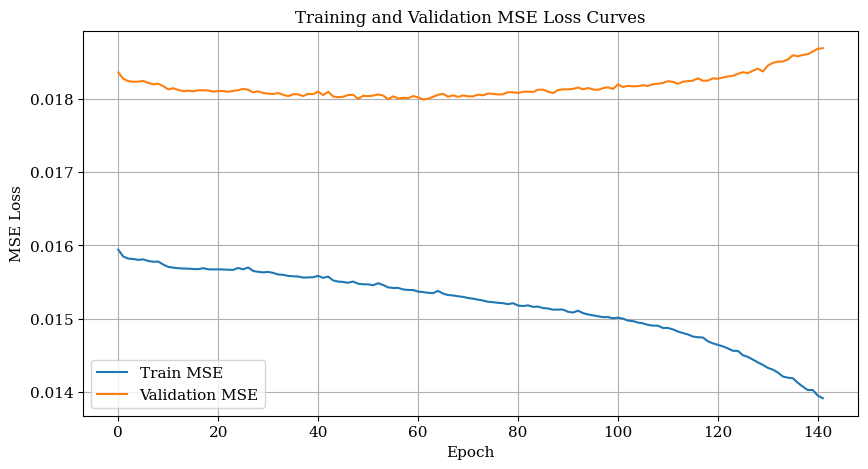

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.015361,0.017950,0.019344,0.255408,0.271153,0.285075
1,(mSHRED): TR+cnn,(T.1.B): mean imputation for missing sensors,0.015406,0.017993,0.019442,0.255280,0.271323,0.284267
2,(mSHRED): TR+cnn,(T.1.C): last-value imputation for missing sen...,0.015430,0.017986,0.019407,0.255855,0.271408,0.284596
3,(mSHRED): GRUD+cnn,(T.2.A): GRUD,0.015382,0.017947,0.019429,0.255484,0.271606,0.284615
4,(mSHRED): Attn-GRUD+cnn,(T.2.B): Attn-GRUD,0.015489,0.018043,0.019502,0.256395,0.272255,0.285157
5,(mSHRED): TR+cnn,(T.3.A): masking,0.015415,0.017991,0.019457,0.256017,0.271837,0.285440
6,(mSHRED): TR+cnn,(T.3.B): masking x2 channels,0.015461,0.017983,0.019431,0.256416,0.271805,0.285267
7,(mSHRED): TR+cnn,(T.3.C): masking hidden space,0.015365,0.017988,0.019443,0.255605,0.271834,0.285331


In [24]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_hidden_mask", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
 )
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    masking_type=MASKING_TYPE,
 )

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.3.C): masking hidden space", masking_type=MASKING_TYPE
 )

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

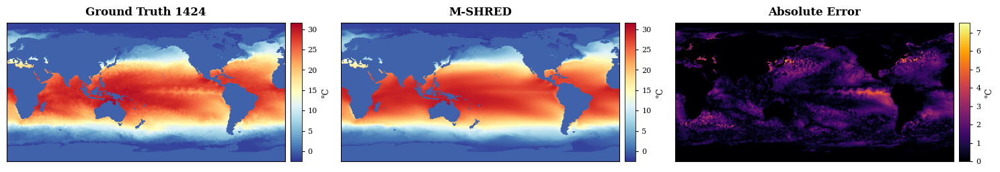

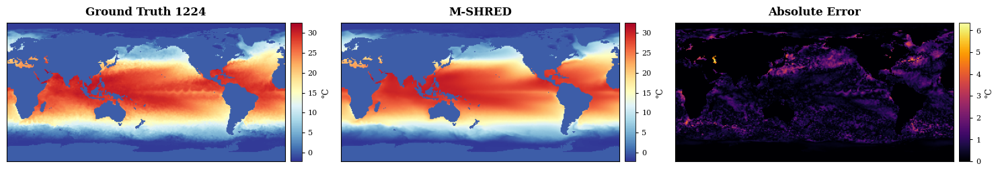

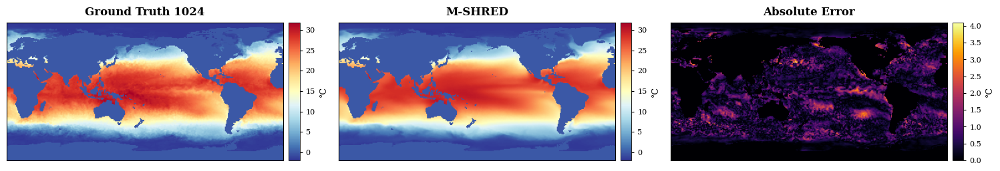

In [25]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
for id in range(3):
    plot_reconstruction(test_reconstruction, X_raw, sst_locs, index=-id*200)

## (T.3.D): Masking MHSA

Starting training...


Training:  33%|███▎      | 132/400 [03:57<08:02,  1.80s/it, Train Loss=0.01349, Val Loss=0.01884, Patience=79, Best Val Loss=0.01798, LR=3.76e-04]

Early stopping at epoch 133
Training completed with best validation loss: 0.0180


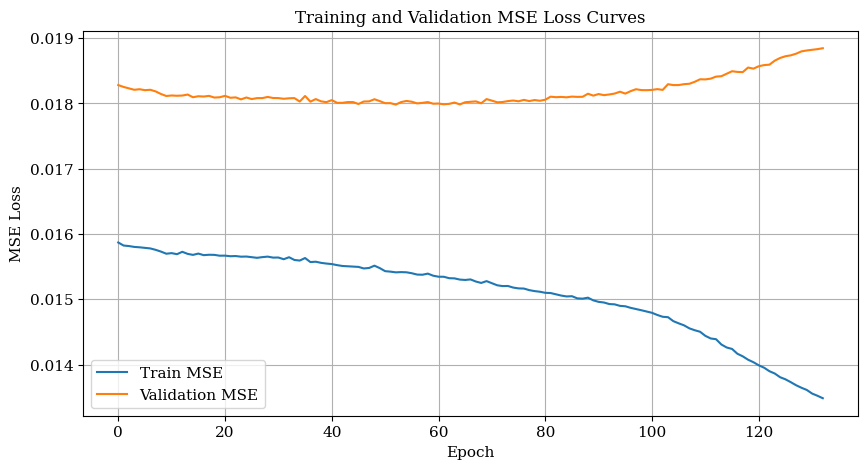

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.015361,0.017950,0.019344,0.255408,0.271153,0.285075
1,(mSHRED): TR+cnn,(T.1.B): mean imputation for missing sensors,0.015406,0.017993,0.019442,0.255280,0.271323,0.284267
2,(mSHRED): TR+cnn,(T.1.C): last-value imputation for missing sen...,0.015430,0.017986,0.019407,0.255855,0.271408,0.284596
3,(mSHRED): GRUD+cnn,(T.2.A): GRUD,0.015382,0.017947,0.019429,0.255484,0.271606,0.284615
4,(mSHRED): Attn-GRUD+cnn,(T.2.B): Attn-GRUD,0.015489,0.018043,0.019502,0.256395,0.272255,0.285157
5,(mSHRED): TR+cnn,(T.3.A): masking,0.015415,0.017991,0.019457,0.256017,0.271837,0.285440
6,(mSHRED): TR+cnn,(T.3.B): masking x2 channels,0.015461,0.017983,0.019431,0.256416,0.271805,0.285267
7,(mSHRED): TR+cnn,(T.3.C): masking hidden space,0.015365,0.017988,0.019443,0.255605,0.271834,0.285331
8,(mSHRED): TR+cnn,(T.3.D): masking MHSA,0.015413,0.017982,0.019425,0.256005,0.271742,0.285192


In [26]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_attn_mask", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=False,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
 )
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    masking_type=MASKING_TYPE,
 )

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.3.D): masking MHSA", masking_type=MASKING_TYPE
 )

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

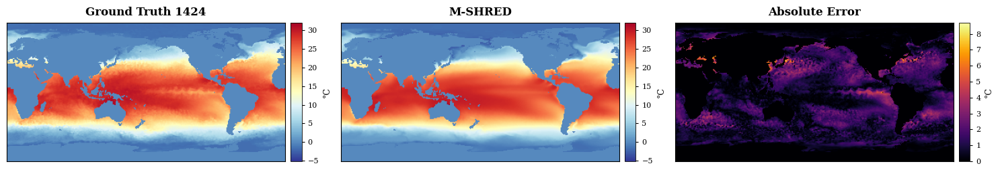

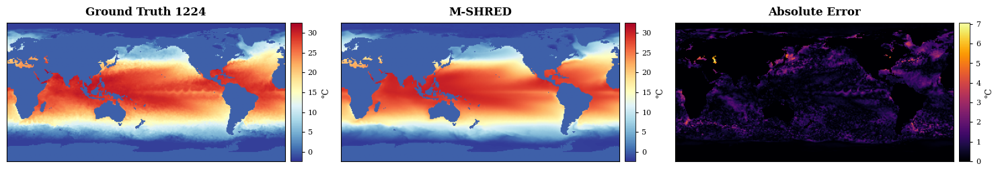

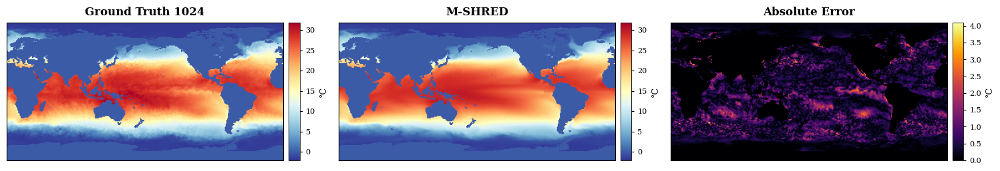

In [27]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
for id in range(3):
    plot_reconstruction(test_reconstruction, X_raw, sst_locs, index=-id*200)

## (T.3.E): Masking x2 channels + MHSA

Starting training...


Training:  35%|███▍      | 139/400 [04:17<08:04,  1.86s/it, Train Loss=0.01409, Val Loss=0.01852, Patience=79, Best Val Loss=0.01797, LR=3.63e-04]

Early stopping at epoch 140
Training completed with best validation loss: 0.0180


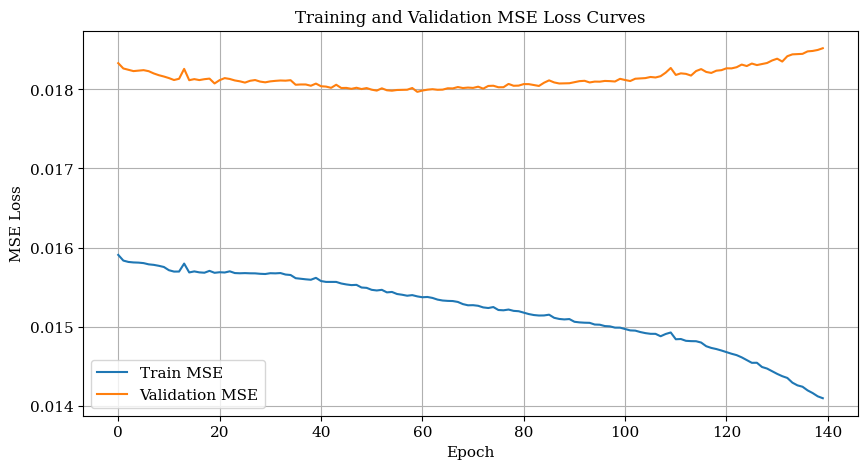

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.015361,0.017950,0.019344,0.255408,0.271153,0.285075
1,(mSHRED): TR+cnn,(T.1.B): mean imputation for missing sensors,0.015406,0.017993,0.019442,0.255280,0.271323,0.284267
2,(mSHRED): TR+cnn,(T.1.C): last-value imputation for missing sen...,0.015430,0.017986,0.019407,0.255855,0.271408,0.284596
3,(mSHRED): GRUD+cnn,(T.2.A): GRUD,0.015382,0.017947,0.019429,0.255484,0.271606,0.284615
4,(mSHRED): Attn-GRUD+cnn,(T.2.B): Attn-GRUD,0.015489,0.018043,0.019502,0.256395,0.272255,0.285157
5,(mSHRED): TR+cnn,(T.3.A): masking,0.015415,0.017991,0.019457,0.256017,0.271837,0.285440
6,(mSHRED): TR+cnn,(T.3.B): masking x2 channels,0.015461,0.017983,0.019431,0.256416,0.271805,0.285267
7,(mSHRED): TR+cnn,(T.3.C): masking hidden space,0.015365,0.017988,0.019443,0.255605,0.271834,0.285331
8,(mSHRED): TR+cnn,(T.3.D): masking MHSA,0.015413,0.017982,0.019425,0.256005,0.271742,0.285192
9,(mSHRED): TR+cnn,(T.3.E): masking x2 channels + MHSA,0.015381,0.017970,0.019442,0.255742,0.271673,0.285332


In [28]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_attn_mask", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=True,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
 )
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    masking_type=MASKING_TYPE,
 )

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.3.E): masking x2 channels + MHSA", masking_type=MASKING_TYPE
 )

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

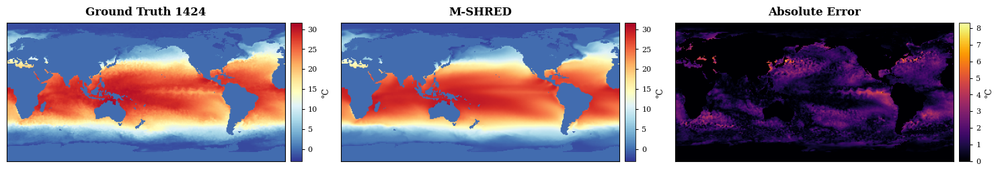

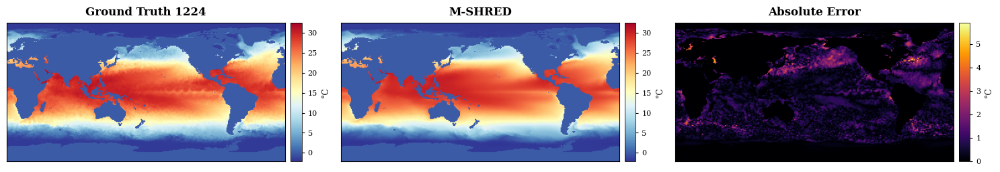

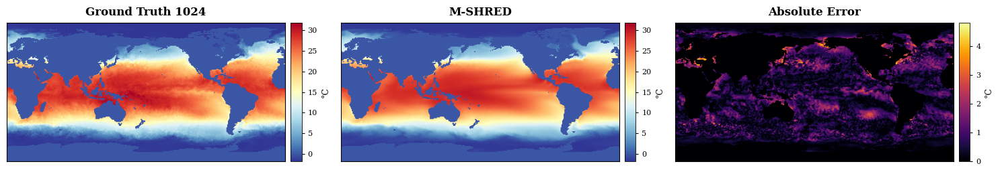

In [29]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
for id in range(3):
    plot_reconstruction(test_reconstruction, X_raw, sst_locs, index=-id*200)

## (T.3.F): Masking MHSA learned

Starting training...


Training:  37%|███▋      | 148/400 [06:04<10:20,  2.46s/it, Train Loss=0.01325, Val Loss=0.01893, Patience=79, Best Val Loss=0.01798, LR=3.47e-04]

Early stopping at epoch 149
Training completed with best validation loss: 0.0180


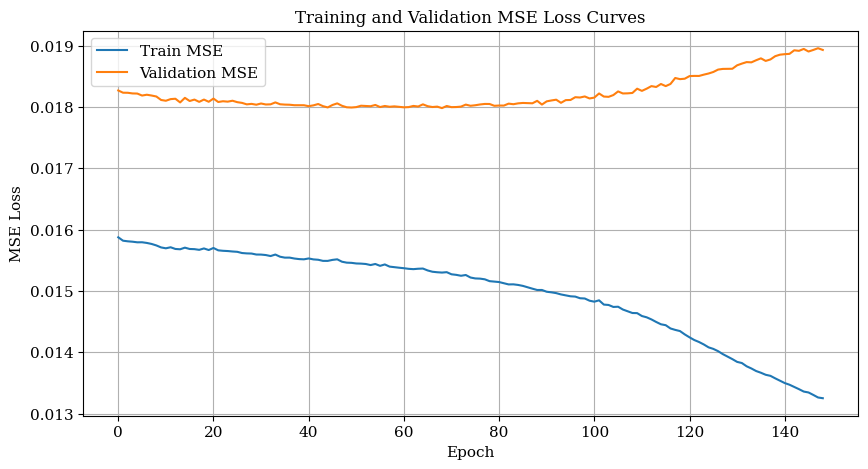

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.015361,0.017950,0.019344,0.255408,0.271153,0.285075
1,(mSHRED): TR+cnn,(T.1.B): mean imputation for missing sensors,0.015406,0.017993,0.019442,0.255280,0.271323,0.284267
2,(mSHRED): TR+cnn,(T.1.C): last-value imputation for missing sen...,0.015430,0.017986,0.019407,0.255855,0.271408,0.284596
3,(mSHRED): GRUD+cnn,(T.2.A): GRUD,0.015382,0.017947,0.019429,0.255484,0.271606,0.284615
4,(mSHRED): Attn-GRUD+cnn,(T.2.B): Attn-GRUD,0.015489,0.018043,0.019502,0.256395,0.272255,0.285157
5,(mSHRED): TR+cnn,(T.3.A): masking,0.015415,0.017991,0.019457,0.256017,0.271837,0.285440
6,(mSHRED): TR+cnn,(T.3.B): masking x2 channels,0.015461,0.017983,0.019431,0.256416,0.271805,0.285267
7,(mSHRED): TR+cnn,(T.3.C): masking hidden space,0.015365,0.017988,0.019443,0.255605,0.271834,0.285331
8,(mSHRED): TR+cnn,(T.3.D): masking MHSA,0.015413,0.017982,0.019425,0.256005,0.271742,0.285192
9,(mSHRED): TR+cnn,(T.3.E): masking x2 channels + MHSA,0.015381,0.017970,0.019442,0.255742,0.271673,0.285332


In [30]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_learned_mask", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
 )
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    masking_type=MASKING_TYPE,
 )

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.3.F): masking MHSA learned", masking_type=MASKING_TYPE
 )

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

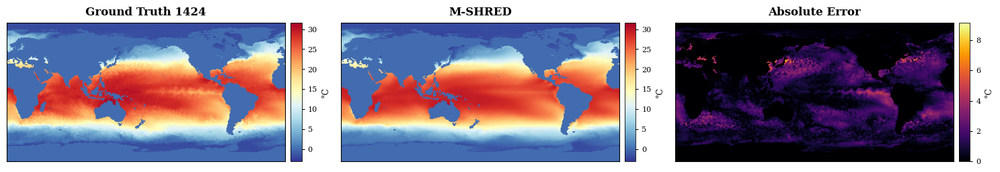

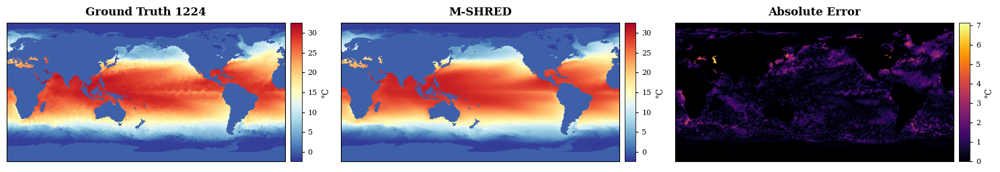

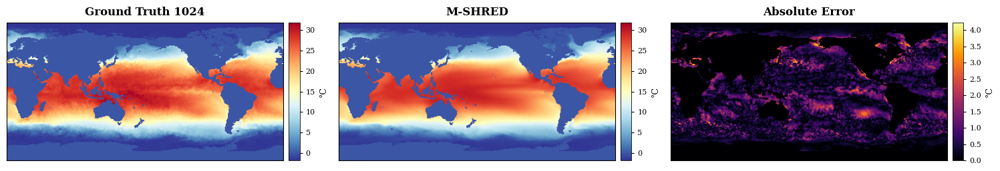

In [31]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
for id in range(3):
    plot_reconstruction(test_reconstruction, X_raw, sst_locs, index=-id*200)

## (T.3.G): Masking x2 channels + MHSA learned

Starting training...


Training:  34%|███▍      | 135/400 [05:19<10:27,  2.37s/it, Train Loss=0.01343, Val Loss=0.01876, Patience=79, Best Val Loss=0.01799, LR=3.70e-04]

Early stopping at epoch 136
Training completed with best validation loss: 0.0180


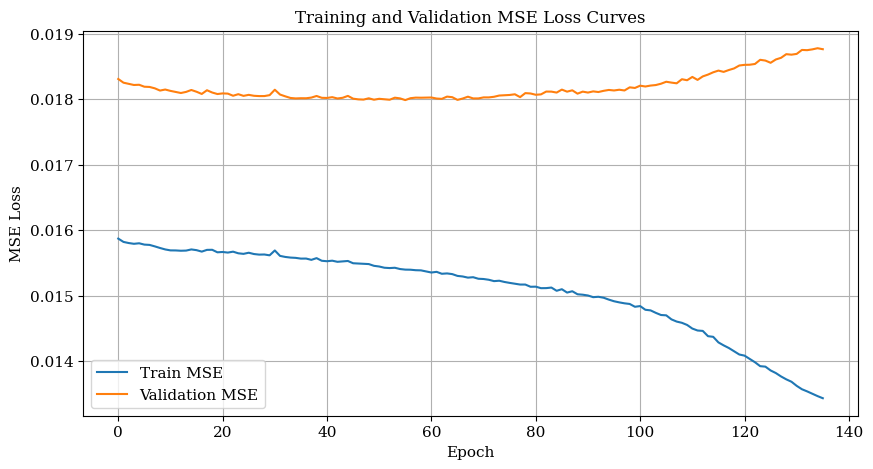

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.015361,0.017950,0.019344,0.255408,0.271153,0.285075
1,(mSHRED): TR+cnn,(T.1.B): mean imputation for missing sensors,0.015406,0.017993,0.019442,0.255280,0.271323,0.284267
2,(mSHRED): TR+cnn,(T.1.C): last-value imputation for missing sen...,0.015430,0.017986,0.019407,0.255855,0.271408,0.284596
3,(mSHRED): GRUD+cnn,(T.2.A): GRUD,0.015382,0.017947,0.019429,0.255484,0.271606,0.284615
4,(mSHRED): Attn-GRUD+cnn,(T.2.B): Attn-GRUD,0.015489,0.018043,0.019502,0.256395,0.272255,0.285157
5,(mSHRED): TR+cnn,(T.3.A): masking,0.015415,0.017991,0.019457,0.256017,0.271837,0.285440
6,(mSHRED): TR+cnn,(T.3.B): masking x2 channels,0.015461,0.017983,0.019431,0.256416,0.271805,0.285267
7,(mSHRED): TR+cnn,(T.3.C): masking hidden space,0.015365,0.017988,0.019443,0.255605,0.271834,0.285331
8,(mSHRED): TR+cnn,(T.3.D): masking MHSA,0.015413,0.017982,0.019425,0.256005,0.271742,0.285192
9,(mSHRED): TR+cnn,(T.3.E): masking x2 channels + MHSA,0.015381,0.017970,0.019442,0.255742,0.271673,0.285332


In [32]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_learned_mask", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=True,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
 )
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    masking_type=MASKING_TYPE,
 )

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.3.G): masking x2 channels + MHSA learned", masking_type=MASKING_TYPE
 )

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

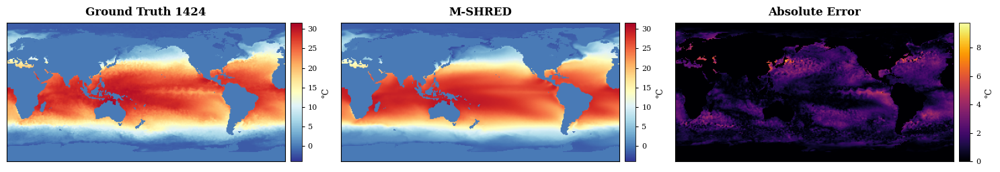

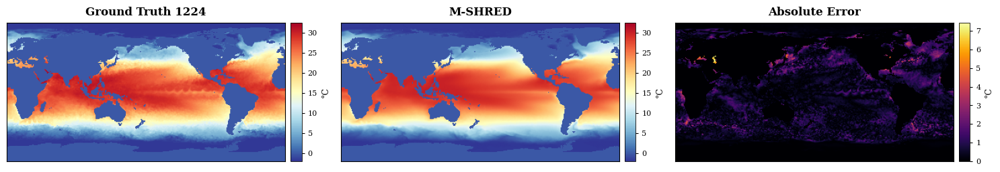

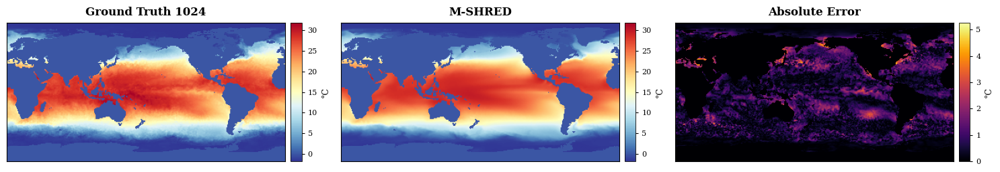

In [33]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
for id in range(3):
    plot_reconstruction(test_reconstruction, X_raw, sst_locs, index=-id*200)

## Results

In [34]:
dataframe_errors = pd.read_csv("dataframe_errors.csv")  # reload to ensure clean data
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.015361,0.017950,0.019344,0.255408,0.271153,0.285075
1,(mSHRED): TR+cnn,(T.1.B): mean imputation for missing sensors,0.015406,0.017993,0.019442,0.255280,0.271323,0.284267
2,(mSHRED): TR+cnn,(T.1.C): last-value imputation for missing sen...,0.015430,0.017986,0.019407,0.255855,0.271408,0.284596
3,(mSHRED): GRUD+cnn,(T.2.A): GRUD,0.015382,0.017947,0.019429,0.255484,0.271606,0.284615
4,(mSHRED): Attn-GRUD+cnn,(T.2.B): Attn-GRUD,0.015489,0.018043,0.019502,0.256395,0.272255,0.285157
5,(mSHRED): TR+cnn,(T.3.A): masking,0.015415,0.017991,0.019457,0.256017,0.271837,0.285440
6,(mSHRED): TR+cnn,(T.3.B): masking x2 channels,0.015461,0.017983,0.019431,0.256416,0.271805,0.285267
7,(mSHRED): TR+cnn,(T.3.C): masking hidden space,0.015365,0.017988,0.019443,0.255605,0.271834,0.285331
8,(mSHRED): TR+cnn,(T.3.D): masking MHSA,0.015413,0.017982,0.019425,0.256005,0.271742,0.285192
9,(mSHRED): TR+cnn,(T.3.E): masking x2 channels + MHSA,0.015381,0.017970,0.019442,0.255742,0.271673,0.285332


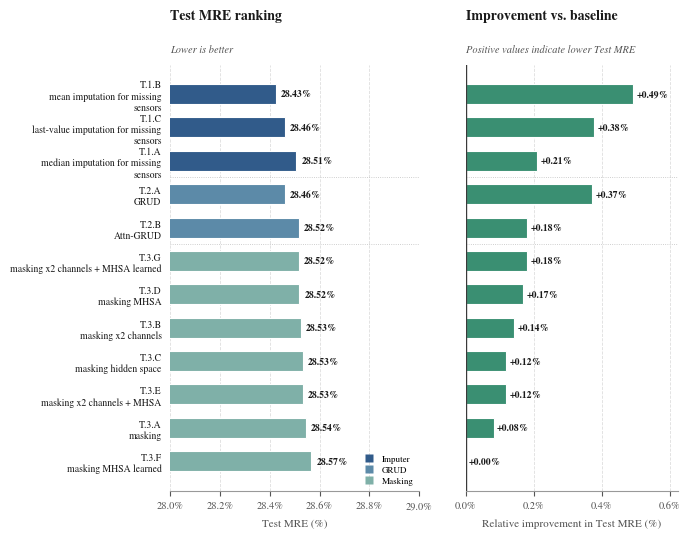

In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import textwrap
from matplotlib.ticker import FuncFormatter

# ============================================================
# PAPER-READY SETTINGS
# ============================================================
# - Vector-safe fonts (Type 42) so PDF/EPS embed correctly in LaTeX
# - Serif font to match most journal body text (swap to sans if your
#   venue uses a sans-serif font, e.g. "DejaVu Sans" / "Arial")
# - White background (no off-white/slide-deck backdrop)
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Nimbus Roman", "DejaVu Serif"],
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
    "axes.unicode_minus": False,
})

# Set BASELINE_PATTERN to the substring identifying your baseline row
# (e.g. "T.0"). If no row matches, the code falls back to using the
# worst-performing (highest test-mre) row as the reference point.
BASELINE_PATTERN = "T.0"

# ============================================================
# LOAD DATA
# ============================================================

dataframe_errors = pd.read_csv("dataframe_errors.csv")

df_plot = dataframe_errors.copy()

# ------------------------------------------------------------
# Parse "(TAG): description" -> separate columns, and pull the
# ablation-group number out of the tag (T.1 / T.2 / T.3 / ...).
# Grouping keeps a long ablation table legible: rows are blocked
# by experiment family instead of one flat 13-row ranking.
# ------------------------------------------------------------
extracted = df_plot["type"].str.extract(r"^\(([^)]+)\):\s*(.*)$")
df_plot["tag"] = extracted[0].fillna(df_plot["type"])
df_plot["desc"] = extracted[1].fillna("")

df_plot["group"] = df_plot["tag"].str.extract(r"^T\.(\d+)").fillna("0")
group_order = sorted(df_plot["group"].unique(), key=lambda g: int(g))

df_plot = (
    df_plot
    .sort_values(["group", "test-mre"])
    .reset_index(drop=True)
)

baseline_mask = df_plot["type"].str.contains(BASELINE_PATTERN, regex=False)

if baseline_mask.any():
    baseline_idx = df_plot.index[baseline_mask][0]
    baseline_test_mre = df_plot.loc[baseline_idx, "test-mre"]
else:
    baseline_idx = None
    baseline_test_mre = df_plot["test-mre"].max()

# Convert to percentage
df_plot["test-mre_%"] = 100 * df_plot["test-mre"]
df_plot["improvement_vs_baseline_%"] = (
    100 * (baseline_test_mre - df_plot["test-mre"]) / baseline_test_mre
)

# Wrap the description only (tag is shown separately via color), which
# keeps rows compact when there are many of them
df_plot["desc_wrapped"] = [
    "\n".join(textwrap.wrap(str(s), width=34))
    for s in df_plot["desc"]
]
df_plot["type_wrapped"] = df_plot["tag"] + "\n" + df_plot["desc_wrapped"]

n_models = len(df_plot)
y = np.arange(n_models)

# ============================================================
# STYLE — print-safe palette (also fine in grayscale)
# ============================================================

BLUE = "#315B8A"
GREEN = "#3A8F72"
RED = "#C65A54"
GOLD = "#D39B32"

TEXT = "#1A1A1A"
SECONDARY = "#555555"
GRID = "#DADADA"

# One color per ablation group (T.1 / T.2 / T.3 / ...), reused across
# both panels' left-side tick coloring so the reader can track a family
# of experiments down the whole table.
# Map each group number to a human-readable name for the legend; any
# group not listed here falls back to "Group N".
GROUP_NAMES = {
    "1": "Imputer",
    "2": "GRUD",
    "3": "Masking",
}
GROUP_PALETTE = ["#315B8A", "#5C8AA8", "#7FB0A8", "#A8A040", "#8A5C9E"]
group_colors = {
    g: GROUP_PALETTE[i % len(GROUP_PALETTE)]
    for i, g in enumerate(group_order)
}
group_labels = {
    g: GROUP_NAMES.get(g, f"Group {g}")
    for g in group_order
}

# ============================================================
# FIGURE — sized for a double-column journal figure
# (7.16 in is the standard IEEE/Elsevier two-column text width;
#  use 3.5 in single-column if you stack panels vertically instead)
# ============================================================

FIG_WIDTH_IN = 7.16
fig_height = max(2.6, 0.34 * n_models + 1.6)

fig, axes = plt.subplots(
    1, 2,
    figsize=(FIG_WIDTH_IN, fig_height),
    gridspec_kw={"width_ratios": [1.08, 0.92], "wspace": 0.20},
)
fig.patch.set_facecolor("white")
for ax in axes:
    ax.set_facecolor("white")


def add_panel_title(ax, title, subtitle):
    ax.text(0.0, 1.10, title, transform=ax.transAxes, fontsize=10,
             fontweight="bold", color=TEXT, ha="left", va="bottom")
    ax.text(0.0, 1.025, subtitle, transform=ax.transAxes, fontsize=7.5,
             color=SECONDARY, ha="left", va="bottom", style="italic")


# ============================================================
# LEFT PANEL — TEST MRE RANKING
# ============================================================

ax = axes[0]
bar_colors_left = [group_colors[g] for g in df_plot["group"]]
bars = ax.barh(y, df_plot["test-mre_%"], height=0.6, color=bar_colors_left,
                edgecolor="white", linewidth=0.8)

if baseline_idx is not None:
    bars[baseline_idx].set_color(GOLD)

ax.set_yticks(y)
ax.set_yticklabels(df_plot["type_wrapped"], fontsize=7, color=TEXT)
ax.invert_yaxis()

# Thin separators between ablation groups
group_boundaries = np.where(df_plot["group"].values[:-1] != df_plot["group"].values[1:])[0]
for b in group_boundaries:
    ax.axhline(b + 0.5, color="#BFBFBF", linewidth=0.6, linestyle=":", zorder=1)

add_panel_title(ax, "Test MRE ranking", "Lower is better")
ax.set_xlabel("Test MRE (%)", fontsize=8, color=SECONDARY, labelpad=6)

# Auto-range with a small margin instead of a hardcoded 12-15 window,
# so the script generalizes to other data
lo = np.floor(df_plot["test-mre_%"].min() * 4) / 4 - 0.25
hi = np.ceil(df_plot["test-mre_%"].max() * 4) / 4 + 0.25
ax.set_xlim(lo, hi)

ax.grid(axis="x", linestyle="--", linewidth=0.6, color=GRID, alpha=0.9)
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)

for i, value in enumerate(df_plot["test-mre_%"]):
    ax.text(min(value + 0.02, hi - 0.04), i, f"{value:.2f}%", va="center",
             ha="left", fontsize=7, fontweight="bold", color=TEXT)

# Legend mapping group color -> group tag prefix (e.g. "T.1", "T.2")
legend_handles = [
    plt.Line2D([0], [0], marker="s", linestyle="none", markersize=6,
               markerfacecolor=group_colors[g], markeredgecolor="none",
               label=group_labels[g])
    for g in group_order
]
ax.legend(
    handles=legend_handles,
    loc="lower right",
    fontsize=6.5,
    frameon=False,
    handletextpad=0.4,
    labelspacing=0.3,
    borderaxespad=0.2,
)

# ============================================================
# RIGHT PANEL — IMPROVEMENT VS BASELINE
# ============================================================

ax = axes[1]
improvement = df_plot["improvement_vs_baseline_%"]

bar_colors = [
    GREEN if v > 1e-4 else RED if v < -1e-4 else "#8A8A8A"
    for v in improvement
]

ax.barh(y, improvement, height=0.6, color=bar_colors,
        edgecolor="white", linewidth=0.8)
ax.set_yticks(y)
ax.set_yticklabels([])
ax.invert_yaxis()
ax.axvline(0, color="#3A3A3A", linewidth=1.0, zorder=3)

for b in group_boundaries:
    ax.axhline(b + 0.5, color="#BFBFBF", linewidth=0.6, linestyle=":", zorder=1)

baseline_label = (
    df_plot.loc[baseline_idx, "type"] if baseline_idx is not None
    else "worst configuration"
)
add_panel_title(ax, "Improvement vs. baseline",
                 "Positive values indicate lower Test MRE")
ax.set_xlabel("Relative improvement in Test MRE (%)", fontsize=8,
              color=SECONDARY, labelpad=6)

ax.grid(axis="x", linestyle="--", linewidth=0.6, color=GRID, alpha=0.9)
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)

max_positive = max(improvement.max(), 0.5)
max_negative = min(improvement.min(), 0)
ax.set_xlim(max_negative * 1.25, max_positive * 1.25)

max_abs = max(abs(improvement.min()), abs(improvement.max()), 0.5)
for i, value in enumerate(improvement):
    if value >= 0:
        ax.text(value + 0.02 * max_abs, i, f"+{value:.2f}%", va="center",
                 ha="left", fontsize=7, fontweight="bold", color=TEXT)
    else:
        ax.text(value - 0.02 * max_abs, i, f"{value:.2f}%", va="center",
                 ha="right", fontsize=7, fontweight="bold", color=TEXT)

# ============================================================
# AXIS CLEANUP
# ============================================================

for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(False)
    ax.spines["bottom"].set_color("#999999")
    ax.tick_params(axis="y", length=0, pad=6)
    ax.tick_params(axis="x", colors=SECONDARY, labelsize=7.5)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x:.1f}%"))

if baseline_idx is not None:
    tick = axes[0].get_yticklabels()[baseline_idx]
    tick.set_fontweight("bold")
    tick.set_color("#9A711E")

# No in-image suptitle/caption text: papers caption figures via
# \caption{...} in LaTeX. If you want a caption note in the image
# anyway (e.g. for a slide reuse), uncomment below:
#
# fig.text(0.01, 0.01, f"Baseline: {baseline_label}", fontsize=6.5,
#           color=SECONDARY)

fig.subplots_adjust(top=0.88, bottom=0.13, left=0.27, right=0.98, wspace=0.22)
